# AI Carbon-Aware Cloud Scheduler

## Exploratory Data Analysis

This notebook is used to understand the carbon-intensity
and workload datasets before feature engineering and
machine learning model training.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
carbon = pd.read_csv("../data/preprocessed/carbon_intensity.csv")

carbon.head()

,provider,region,timestamp,carbon_intensity_gco2_kwh,renewable_percentage
0,gcp,us-west4,2026-08-14 04:05:40.897319+00:00,489.6,0.2
1,gcp,us-west4,2026-08-14 06:11:06.799484+00:00,489.6,0.2
2,azure,westus3,2026-08-14 06:11:06.799484+00:00,398.4,11.1
3,gcp,us-west4,2026-08-14 08:12:55.988707+00:00,489.6,0.2
4,azure,westus3,2026-08-14 08:12:55.988707+00:00,398.4,11.1


In [3]:
carbon.shape

(38976, 5)

In [4]:
print(pd.__version__)
print("Notebook is working!")

3.0.6
Notebook is working!


In [5]:
carbon = pd.read_csv("../data/preprocessed/carbon_intensity.csv")

print("Dataset loaded!")
carbon.head()
carbon.shape
carbon.columns

Dataset loaded!


Index(['provider', 'region', 'timestamp', 'carbon_intensity_gco2_kwh',
       'renewable_percentage'],
      dtype='str')

In [6]:
carbon.head()

,provider,region,timestamp,carbon_intensity_gco2_kwh,renewable_percentage
0,gcp,us-west4,2026-08-14 04:05:40.897319+00:00,489.6,0.2
1,gcp,us-west4,2026-08-14 06:11:06.799484+00:00,489.6,0.2
2,azure,westus3,2026-08-14 06:11:06.799484+00:00,398.4,11.1
3,gcp,us-west4,2026-08-14 08:12:55.988707+00:00,489.6,0.2
4,azure,westus3,2026-08-14 08:12:55.988707+00:00,398.4,11.1


In [7]:
carbon.shape

(38976, 5)

In [8]:
carbon.info()

<class 'pandas.DataFrame'>
RangeIndex: 38976 entries, 0 to 38975
Data columns (total 5 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   provider                   38976 non-null  str    
 1   region                     38976 non-null  str    
 2   timestamp                  38976 non-null  str    
 3   carbon_intensity_gco2_kwh  38976 non-null  float64
 4   renewable_percentage       38976 non-null  float64
dtypes: float64(2), str(3)
memory usage: 1.5 MB


In [9]:
carbon.describe()

,carbon_intensity_gco2_kwh,renewable_percentage
count,38976.000000,38976.000000
mean,295.422386,29.984626
std,189.893516,28.908955
min,0.000000,0.000000
25%,120.000000,4.700000
50%,336.100000,22.200000
75%,383.600000,45.000000
max,840.600000,100.000000


In [11]:
import pandas as pd
import matplotlib.pyplot as plt

history = pd.read_csv("../data/raw/history.csv")

history.head()

,provider,region,timestamp,carbon_intensity_gco2_kwh,renewable_percentage
0,aws,af-south-1,2026-08-19T00:53:00.211592+00:00,795.6,5.0
1,aws,af-south-1,2026-08-19T02:17:53.174894+00:00,795.6,5.0
2,aws,af-south-1,2026-08-19T03:42:26.812833+00:00,780.0,8.0
3,aws,af-south-1,2026-08-19T04:34:02.547742+00:00,780.0,8.0
4,aws,af-south-1,2026-08-19T05:25:46.493498+00:00,780.0,8.0


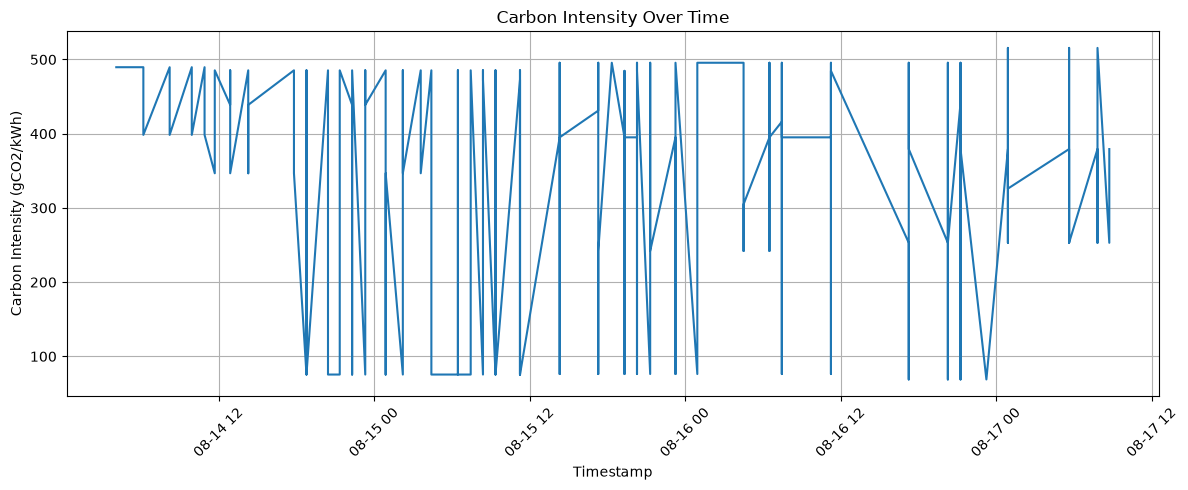

In [12]:
history["timestamp"] = pd.to_datetime(history["timestamp"])
history = history.sort_values("timestamp")

plt.figure(figsize=(12, 5))
plt.plot(
    history["timestamp"].head(500),
    history["carbon_intensity_gco2_kwh"].head(500)
)
plt.title("Carbon Intensity Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Carbon Intensity (gCO2/kWh)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

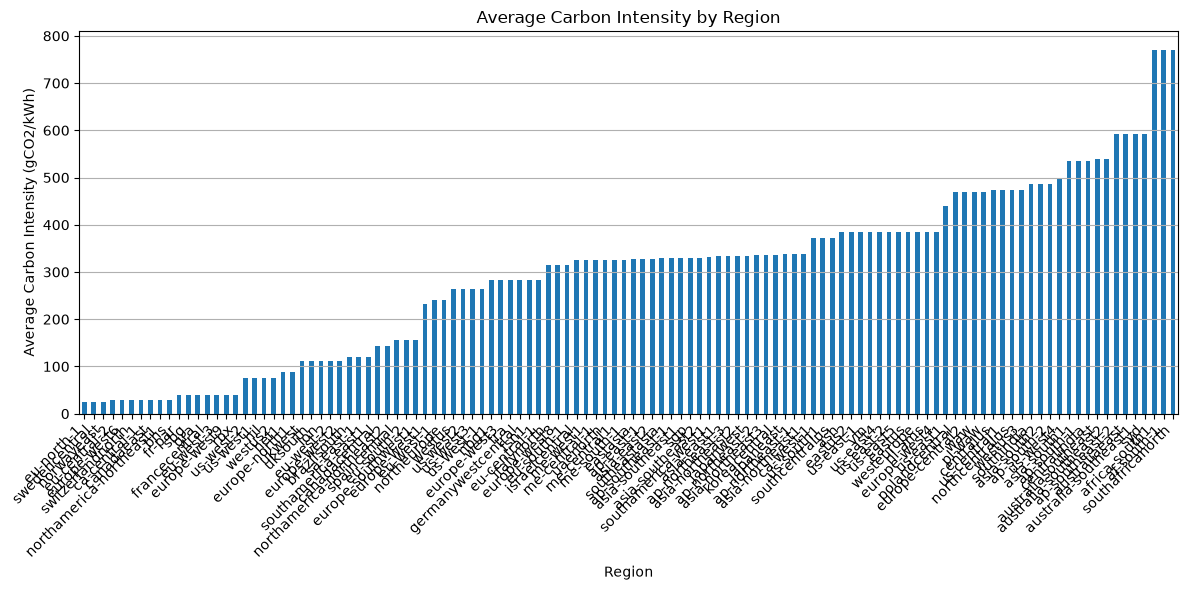

In [13]:
plt.figure(figsize=(12, 6))

region_carbon = (
    history.groupby("region")["carbon_intensity_gco2_kwh"]
    .mean()
    .sort_values()
)

region_carbon.plot(kind="bar")

plt.title("Average Carbon Intensity by Region")
plt.xlabel("Region")
plt.ylabel("Average Carbon Intensity (gCO2/kWh)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

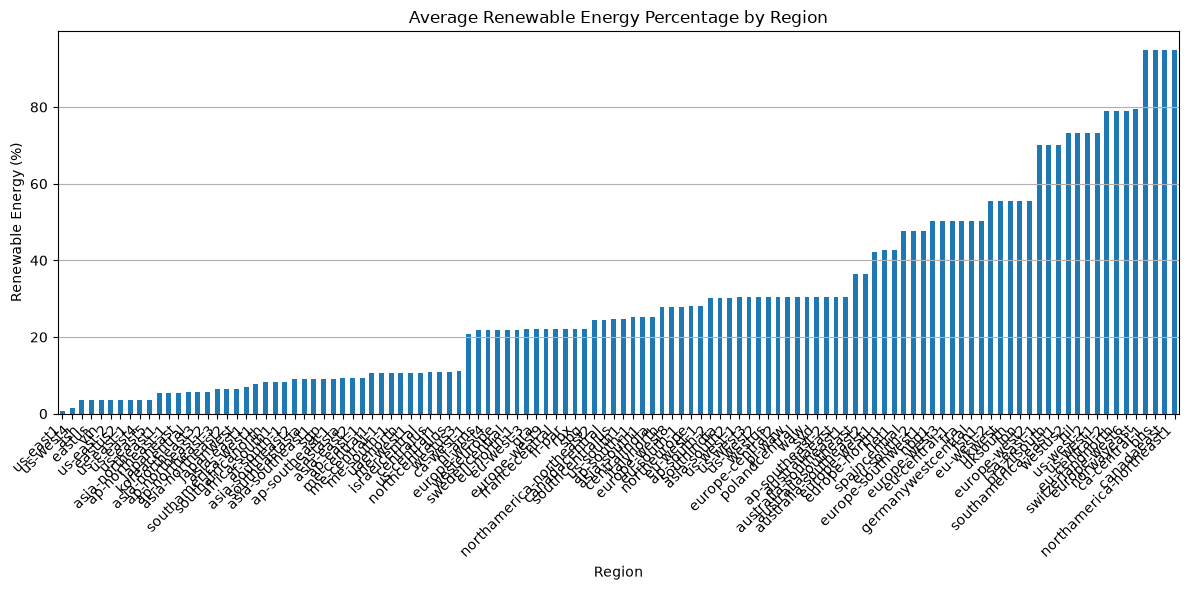

In [14]:
plt.figure(figsize=(12, 6))

renewable = (
    history.groupby("region")["renewable_percentage"]
    .mean()
    .sort_values()
)

renewable.plot(kind="bar")

plt.title("Average Renewable Energy Percentage by Region")
plt.xlabel("Region")
plt.ylabel("Renewable Energy (%)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [16]:
import pandas as pd

workload = pd.read_csv("../data/raw/Cell_c.csv")

print("Workload shape:", workload.shape)
print(workload.columns.tolist())
display(workload.head())

Workload shape: (7200798, 5)
['Job_ID', 'Task_ID', 'Arrival_Time', 'CPU', 'Memory']


,Job_ID,Task_ID,Arrival_Time,CPU,Memory
0,736958118313,0,601263.722,0.017989,0.000057
1,736958118321,0,601339.991,0.008105,0.000057
2,736958118528,0,601975.491,0.112489,0.000237
3,736958125656,0,604299.116,0.055855,0.001207
4,736959135511,0,608551.032,0.323642,0.003185


In [17]:
print("Workload shape:", workload.shape)
print(workload.columns.tolist())
display(workload.head())

Workload shape: (7200798, 5)
['Job_ID', 'Task_ID', 'Arrival_Time', 'CPU', 'Memory']


,Job_ID,Task_ID,Arrival_Time,CPU,Memory
0,736958118313,0,601263.722,0.017989,0.000057
1,736958118321,0,601339.991,0.008105,0.000057
2,736958118528,0,601975.491,0.112489,0.000237
3,736958125656,0,604299.116,0.055855,0.001207
4,736959135511,0,608551.032,0.323642,0.003185


In [ ]:
region_config = pd.read_csv("../data/preprocessed/region_config.csv")
print("Region config shape:", region_config.shape)
print(region_config.columns.tolist())
display(region_config.head())


Region config shape: (1160, 13)
['datacenter_id', 'provider', 'region', 'host_id', 'pes', 'mips_per_pe', 'ram_mb', 'storage_mb', 'bandwidth_mbps', 'idle_power_w', 'max_power_w', 'pue', 'cost_per_hour']


,datacenter_id,provider,region,host_id,pes,mips_per_pe,ram_mb,storage_mb,bandwidth_mbps,idle_power_w,max_power_w,pue,cost_per_hour
0,DC001,aws,af-south-1,H01,4,800,8192,500000,5000,130,262,1.2,0.085
1,DC001,aws,af-south-1,H02,8,1000,16384,1000000,10000,160,324,1.2,0.090
2,DC001,aws,af-south-1,H03,8,1200,16384,1000000,10000,162,326,1.2,0.095
3,DC001,aws,af-south-1,H04,12,1500,24576,1500000,15000,192,388,1.2,0.100
4,DC001,aws,af-south-1,H05,16,2000,32768,2000000,20000,222,450,1.2,0.105


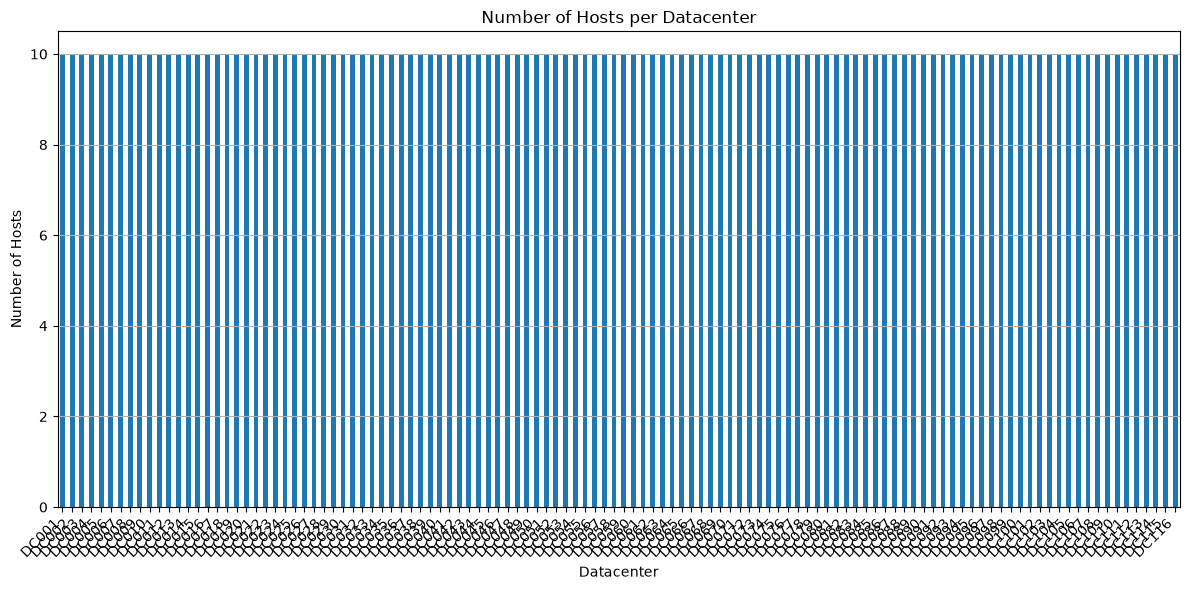

In [23]:


host_counts = region_config.groupby("datacenter_id")["host_id"].nunique()

plt.figure(figsize=(12, 6))
host_counts.plot(kind="bar")

plt.title("Number of Hosts per Datacenter")
plt.xlabel("Datacenter")
plt.ylabel("Number of Hosts")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

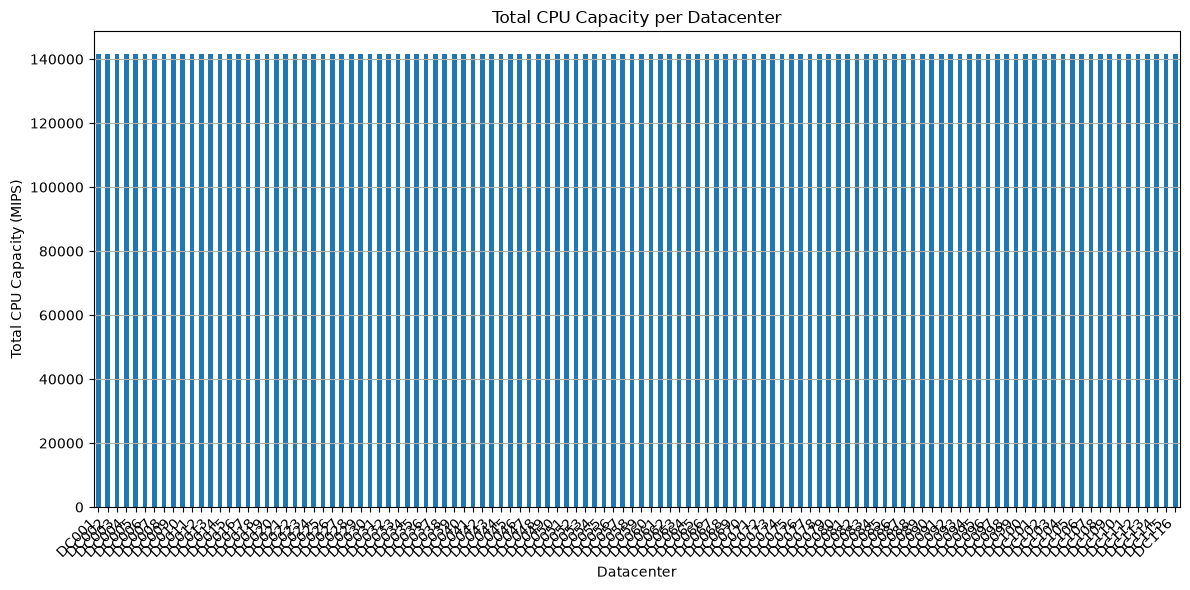

In [24]:
cpu_capacity = (
    region_config.assign(
        total_cpu=region_config["pes"] * region_config["mips_per_pe"]
    )
    .groupby("datacenter_id")["total_cpu"]
    .sum()
)

plt.figure(figsize=(12, 6))
cpu_capacity.plot(kind="bar")

plt.title("Total CPU Capacity per Datacenter")
plt.xlabel("Datacenter")
plt.ylabel("Total CPU Capacity (MIPS)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()